In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import (GridSearchCV,
    KFold,
    cross_val_score
)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully.")



Libraries imported successfully.


In [2]:
# Load the cleaned dataset
df = pd.read_csv("Advertising_Cleaned.csv")

# Create a folder to store all EDA figures
figure_dir = Path("eda_figures")
figure_dir.mkdir(parents=True, exist_ok=True)

# Set visualization style
sns.set_theme(style="whitegrid", palette="deep")

# Columns
feature_columns = ["TV", "Radio", "Newspaper"]
target_column = "Sales"

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

df.head()

Dataset loaded successfully!
Dataset shape: (200, 4)

Columns: ['TV', 'Radio', 'Newspaper', 'Sales']

Missing values:
 TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows: 0


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


In [3]:
# Understand the statistical summary
# Descriptive statistics
summary = df[["TV", "Radio", "Newspaper", "Sales"]].describe().T

summary["median"] = df[
    ["TV", "Radio", "Newspaper", "Sales"]
].median()

summary["skewness"] = df[
    ["TV", "Radio", "Newspaper", "Sales"]
].skew()

display(summary.round(3))

# Save the statistical summary
summary.round(3).to_csv("eda_descriptive_statistics.csv")

,count,mean,std,min,25%,50%,75%,max,median,skewness
TV,200.0,147.042,85.854,0.7,74.375,149.75,218.825,296.4,149.75,-0.070
Radio,200.0,23.264,14.847,0.0,9.975,22.90,36.525,49.6,22.90,0.094
Newspaper,200.0,30.554,21.779,0.3,12.750,25.75,45.100,114.0,25.75,0.895
Sales,200.0,14.022,5.217,1.6,10.375,12.90,17.400,27.0,12.90,0.408


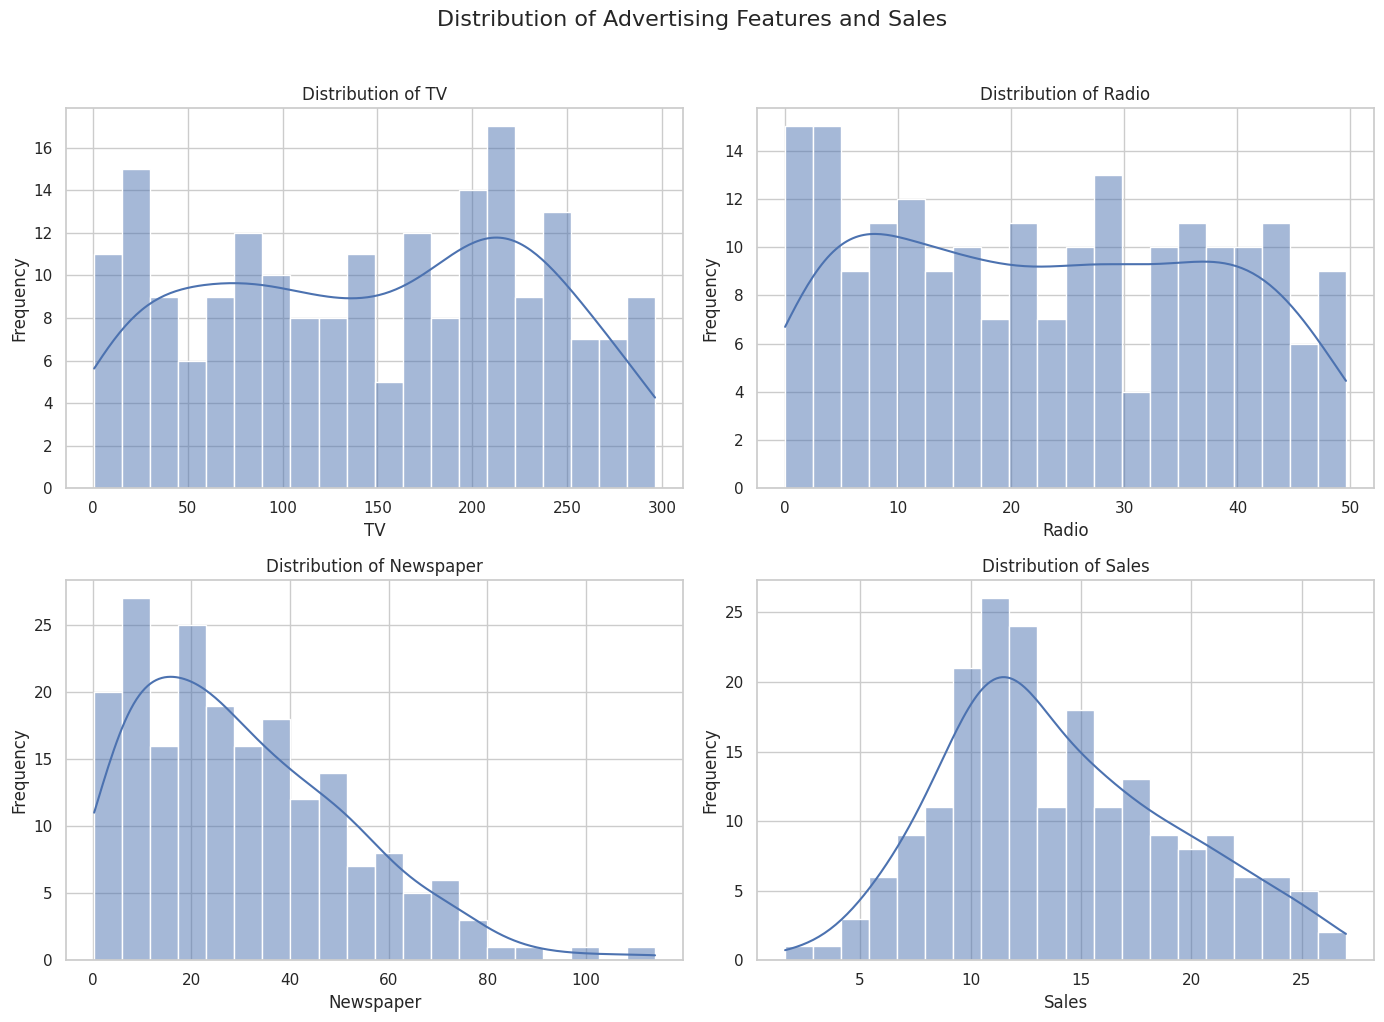

In [4]:
# feature distributions
# Plot histograms for all variables
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

columns = ["TV", "Radio", "Newspaper", "Sales"]

for ax, column in zip(axes, columns):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=20,
        ax=ax
    )
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")

plt.suptitle("Distribution of Advertising Features and Sales",
             fontsize=16, y=1.02)
plt.tight_layout()

plt.savefig(
    figure_dir / "01_feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

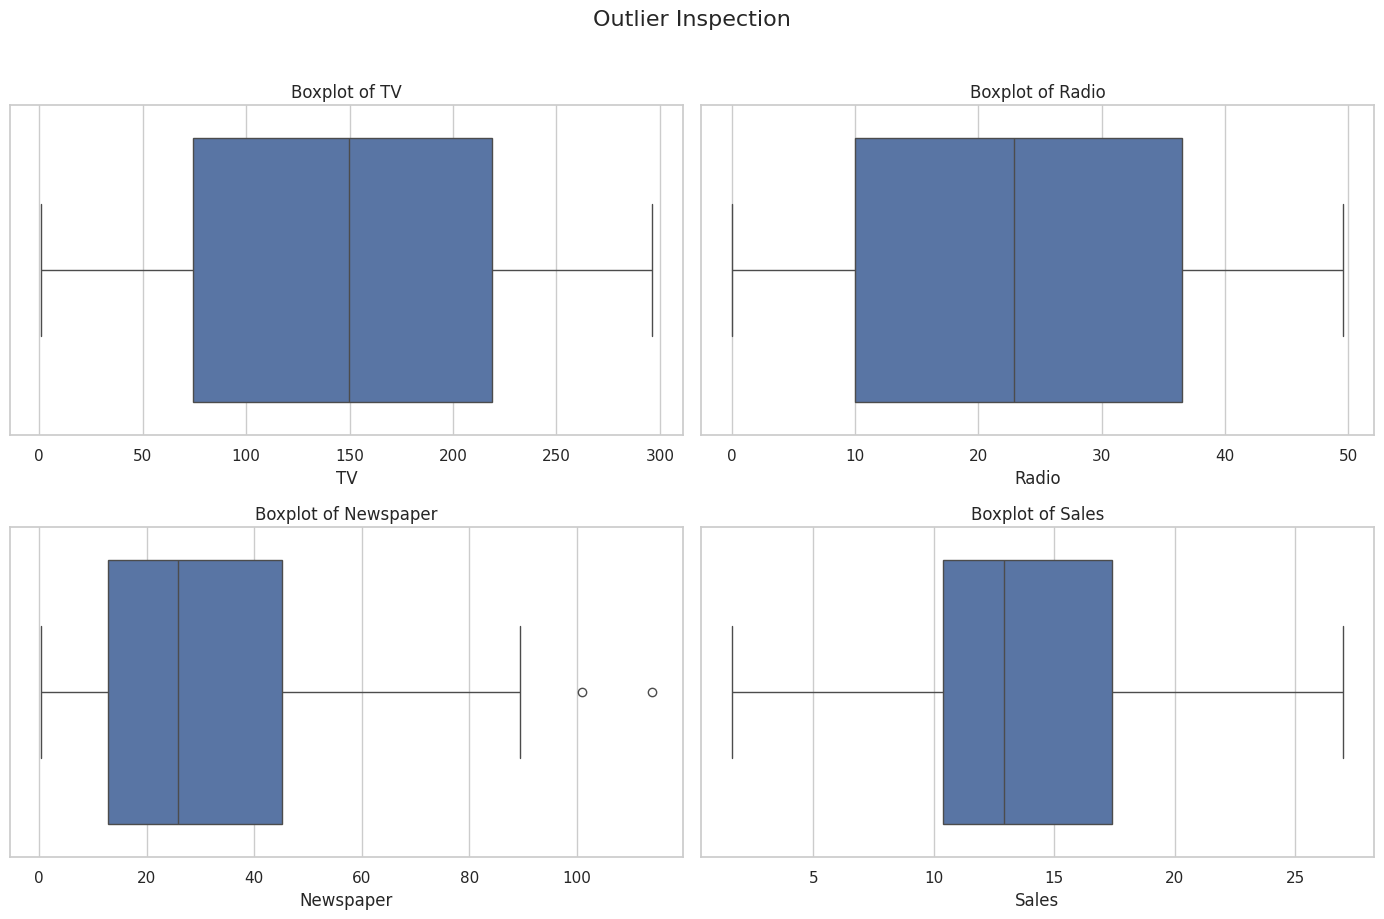

In [5]:
# Detect and visualize potential outliers
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for ax, column in zip(axes, columns):
    sns.boxplot(data=df, x=column, ax=ax)
    ax.set_title(f"Boxplot of {column}")
    ax.set_xlabel(column)

plt.suptitle("Outlier Inspection", fontsize=16, y=1.02)
plt.tight_layout()

plt.savefig(
    figure_dir / "02_outlier_boxplots.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [6]:
# IQR-based outlier inspection
outlier_results = []

for column in columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ][column]

    outlier_results.append({
        "Feature": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Values": outliers.tolist()
    })

outlier_df = pd.DataFrame(outlier_results)
display(outlier_df)

outlier_df.to_csv("eda_outlier_analysis.csv", index=False)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Values
0,TV,-142.3000,435.5000,0,[]
1,Radio,-29.8500,76.3500,0,[]
2,Newspaper,-35.7750,93.6250,2,"[114.0, 100.9]"
3,Sales,-0.1625,27.9375,0,[]


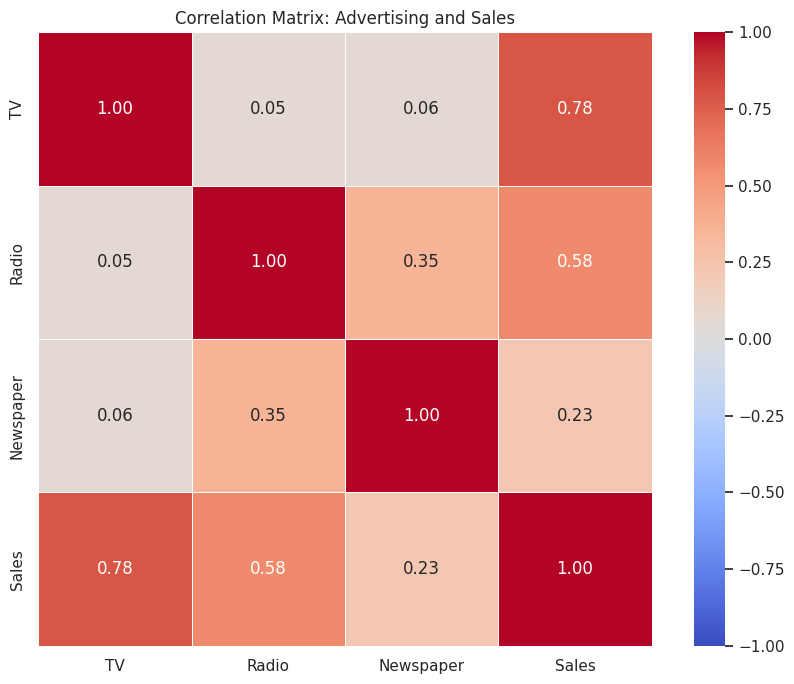

Correlation with Sales:


,Correlation with Sales
TV,0.782224
Radio,0.576223
Newspaper,0.228299


In [7]:
# correlations
correlation_matrix = df[columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Matrix: Advertising and Sales")
plt.tight_layout()

plt.savefig(
    figure_dir / "03_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Correlation with Sales:")
display(
    correlation_matrix["Sales"]
    .drop("Sales")
    .sort_values(ascending=False)
    .to_frame("Correlation with Sales")
)

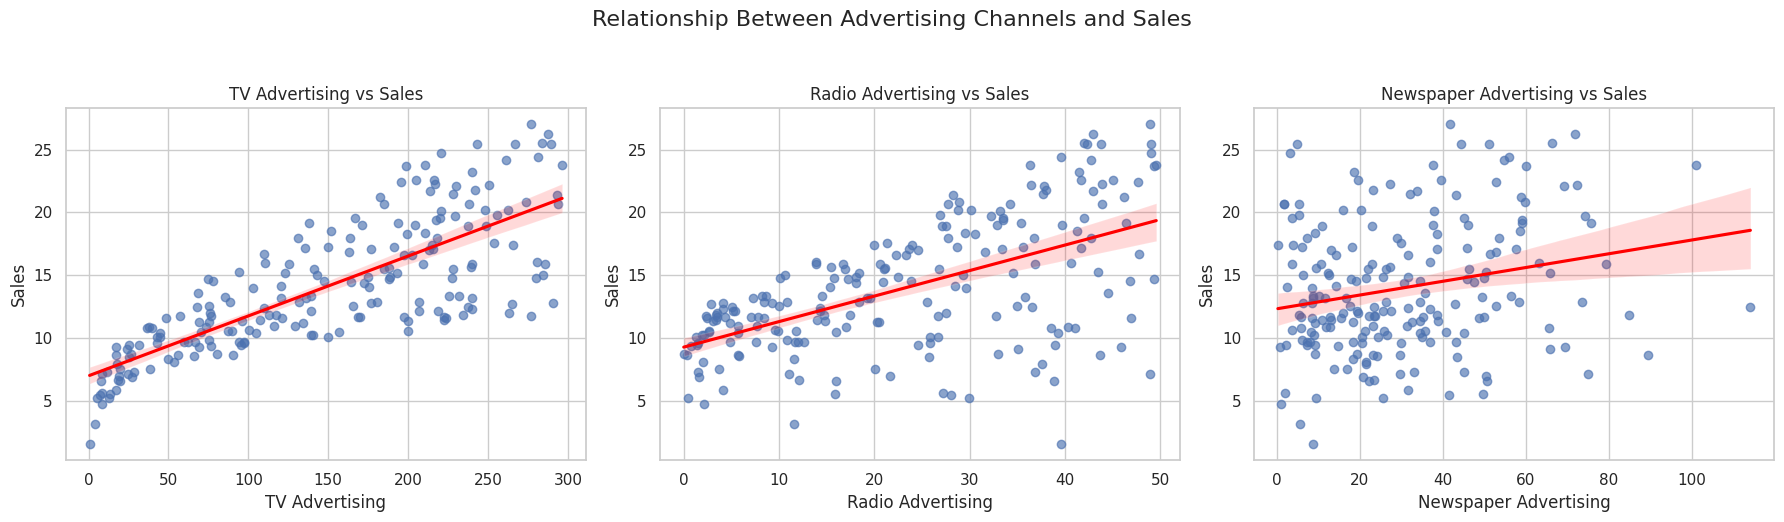

In [8]:
# advertising channel against sales
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, feature_columns):
    sns.regplot(
        data=df,
        x=feature,
        y="Sales",
        ax=ax,
        scatter_kws={"alpha": 0.65},
        line_kws={"color": "red"}
    )

    ax.set_title(f"{feature} Advertising vs Sales")
    ax.set_xlabel(f"{feature} Advertising")
    ax.set_ylabel("Sales")

plt.suptitle("Relationship Between Advertising Channels and Sales",
             fontsize=16, y=1.04)
plt.tight_layout()

plt.savefig(
    figure_dir / "04_advertising_vs_sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

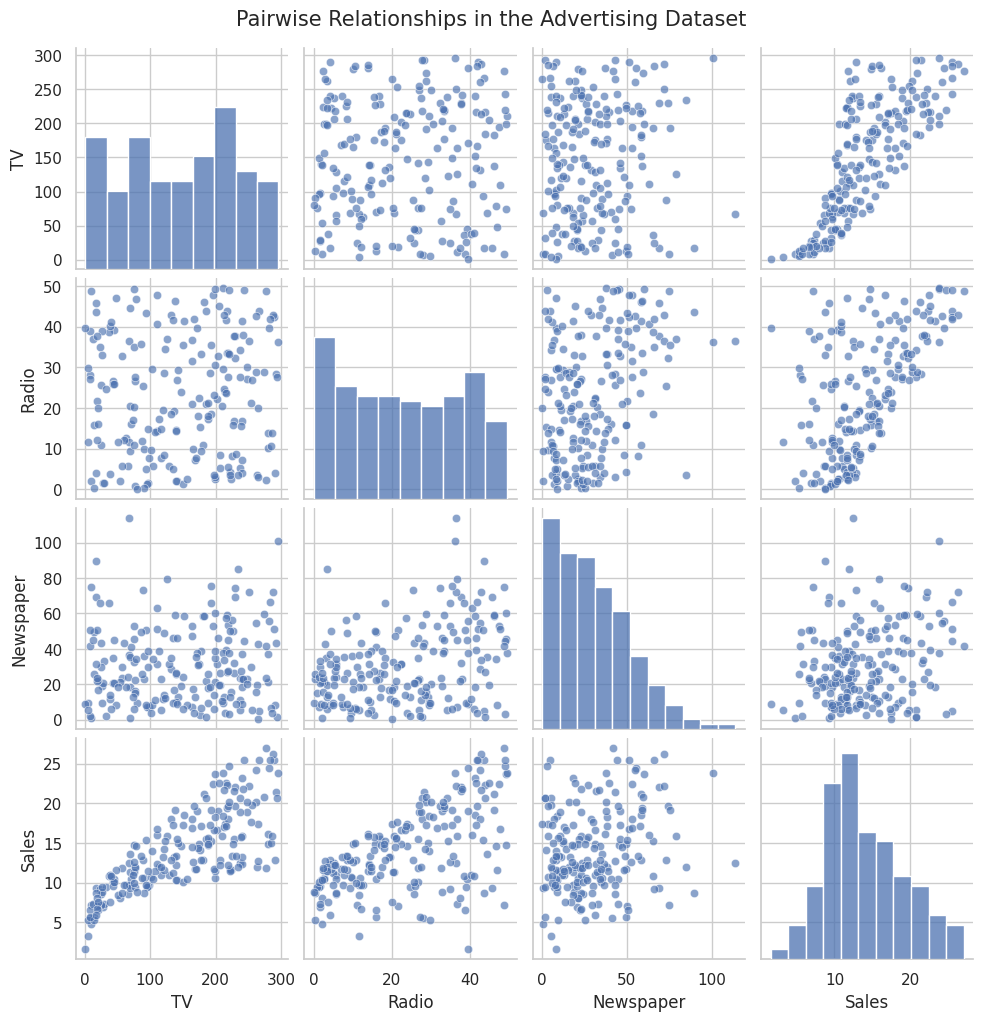

In [9]:
# all feature relationships together
pair_plot = sns.pairplot(
    df[columns],
    diag_kind="hist",
    plot_kws={"alpha": 0.65}
)

pair_plot.fig.suptitle(
    "Pairwise Relationships in the Advertising Dataset",
    y=1.02,
    fontsize=15
)

pair_plot.savefig(
    figure_dir / "05_pairplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [10]:
# Save an EDA findings summary
sales_correlations = (
    df[feature_columns + ["Sales"]]
    .corr()["Sales"]
    .drop("Sales")
    .sort_values(ascending=False)
)

strongest_feature = sales_correlations.index[0]
weakest_feature = sales_correlations.index[-1]

summary_text = f"""
CODEALPHA TASK 4: SALES PREDICTION
EXPLORATORY DATA ANALYSIS SUMMARY
=================================

Dataset rows: {df.shape[0]}
Dataset columns: {df.shape[1]}

Missing values: {df.isnull().sum().sum()}
Duplicate rows: {df.duplicated().sum()}

Average sales: {df['Sales'].mean():.3f}
Median sales: {df['Sales'].median():.3f}
Sales standard deviation: {df['Sales'].std():.3f}

Correlation with Sales:
{sales_correlations.round(3).to_string()}

Strongest linear association: {strongest_feature}
Correlation: {sales_correlations[strongest_feature]:.3f}

Weakest linear association: {weakest_feature}
Correlation: {sales_correlations[weakest_feature]:.3f}

Interpretation:
Correlation indicates association, not causation.
Potential outliers should be investigated before removal.
This dataset has no date or audience-segment columns, so
it does not support genuine time-series forecasting or
direct comparisons between demographic segments.
"""

with open("eda_findings_summary.txt", "w", encoding="utf-8") as file:
    file.write(summary_text)

print(summary_text)


CODEALPHA TASK 4: SALES PREDICTION
EXPLORATORY DATA ANALYSIS SUMMARY

Dataset rows: 200
Dataset columns: 4

Missing values: 0
Duplicate rows: 0

Average sales: 14.023
Median sales: 12.900
Sales standard deviation: 5.217

Correlation with Sales:
TV           0.782
Radio        0.576
Newspaper    0.228

Strongest linear association: TV
Correlation: 0.782

Weakest linear association: Newspaper
Correlation: 0.228

Interpretation:
Correlation indicates association, not causation.
Potential outliers should be investigated before removal.
This dataset has no date or audience-segment columns, so
it does not support genuine time-series forecasting or
direct comparisons between demographic segments.



In [11]:
# Verify the saved figures
saved_figures = sorted(figure_dir.glob("*.png"))

print(f"Number of saved figures: {len(saved_figures)}")

for figure in saved_figures:
    print(figure)

Number of saved figures: 14
eda_figures/01_feature_distributions.png
eda_figures/02_outlier_boxplots.png
eda_figures/03_correlation_heatmap.png
eda_figures/04_advertising_vs_sales.png
eda_figures/05_pairplot.png
eda_figures/06_train_test_split.png
eda_figures/07_model_comparison_rmse.png
eda_figures/08_model_comparison_r2.png
eda_figures/09_actual_vs_predicted.png
eda_figures/10_best_model_residuals.png
eda_figures/11_random_forest_feature_importance.png
eda_figures/12_permutation_importance.png
eda_figures/13_advertising_impact_scenarios.png
eda_figures/14_advertising_response_curves.png


**Feature Selection and Train-Test Split**

In [12]:
# Check feature quality before splitting
import numpy as np

# Define X and y from the dataset
X = df[feature_columns]
y = df[target_column]

# Check data types
print("Feature data types:")
print(X.dtypes)

# Check missing values
print("\nMissing values in X:")
print(X.isnull().sum())

print("\nMissing values in y:", y.isnull().sum())

# Check infinite values
print("\nInfinite values in X:")
print(np.isinf(X).sum())

print("\nInfinite values in y:", np.isinf(y).sum())

# Basic validation
assert X.shape[1] == 3, "Expected three input features."
assert len(X) == len(y), "X and y must have the same number of rows."
assert X.isnull().sum().sum() == 0, "Missing values found in X."
assert y.isnull().sum() == 0, "Missing values found in y."
assert np.isfinite(X.to_numpy()).all(), "Infinite or invalid values found in X."
assert np.isfinite(y.to_numpy()).all(), "Infinite or invalid values found in y."

print("\nValidation passed: X and y are ready for splitting.")

Feature data types:
TV           float64
Radio        float64
Newspaper    float64
dtype: object

Missing values in X:
TV           0
Radio        0
Newspaper    0
dtype: int64

Missing values in y: 0

Infinite values in X:
TV           0
Radio        0
Newspaper    0
dtype: int64

Infinite values in y: 0

Validation passed: X and y are ready for splitting.


In [13]:
# Split the dataset into training and testing sets
# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training and testing split completed.")
print("-" * 40)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape:  {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape:  {y_test.shape}")

print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

print(
    f"Training percentage: "
    f"{len(X_train) / len(df) * 100:.1f}%"
)
print(
    f"Testing percentage: "
    f"{len(X_test) / len(df) * 100:.1f}%"
)

Training and testing split completed.
----------------------------------------
X_train shape: (160, 3)
X_test shape:  (40, 3)
y_train shape: (160,)
y_test shape:  (40,)

Training observations: 160
Testing observations: 40
Training percentage: 80.0%
Testing percentage: 20.0%


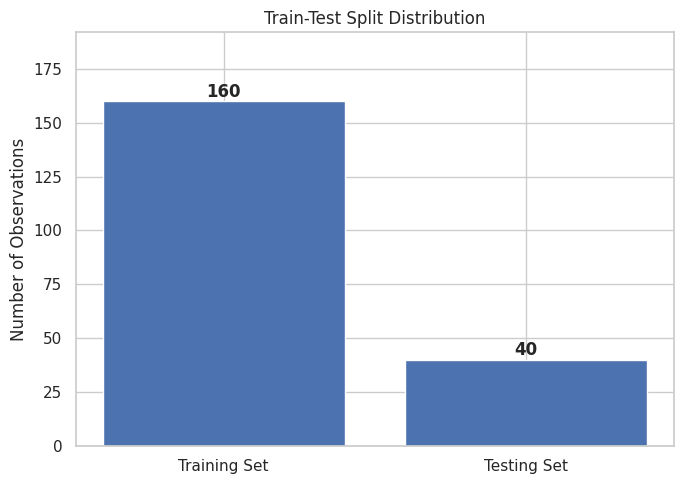

In [14]:
# Visualize the split
training_count = len(X_train)
testing_count = len(X_test)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Training Set", "Testing Set"],
    [training_count, testing_count]
)

plt.title("Train-Test Split Distribution")
plt.ylabel("Number of Observations")

for bar, count in zip(bars, [training_count, testing_count]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        str(count),
        ha="center",
        fontweight="bold"
    )

plt.ylim(0, max(training_count, testing_count) * 1.2)
plt.tight_layout()

# Save figure for the project report
from pathlib import Path

figure_dir = Path("eda_figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "06_train_test_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [15]:
# Inspect the training and testing data
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "Observations": [len(y_train), len(y_test)],
    "Mean Sales": [y_train.mean(), y_test.mean()],
    "Median Sales": [y_train.median(), y_test.median()],
    "Minimum Sales": [y_train.min(), y_test.min()],
    "Maximum Sales": [y_train.max(), y_test.max()]
})

display(split_summary.round(3))

split_summary.to_csv("train_test_split_summary.csv", index=False)

,Dataset,Observations,Mean Sales,Median Sales,Minimum Sales,Maximum Sales
0,Training,160,14.100,13.2,1.6,27.0
1,Testing,40,13.712,11.8,5.3,24.7


In [16]:
# Save the split data
X_train.to_csv("X_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)

y_train.to_frame().to_csv("y_train.csv", index=False)
y_test.to_frame().to_csv("y_test.csv", index=False)

print("Training and testing datasets saved successfully.")

Training and testing datasets saved successfully.


In [17]:
# Initialize and train the models
# Define the regression models
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

# Train each model
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: training completed")

print("\nAll models have been trained successfully.")

Linear Regression: training completed
Decision Tree: training completed
Random Forest: training completed
Gradient Boosting: training completed

All models have been trained successfully.


In [18]:
# Generate predictions and evaluate performance
# Evaluate all trained models on the same test set
results = []
predictions = {}

for name, model in models.items():

    # Predict sales on unseen test observations
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Test_MAE": mae,
        "Test_RMSE": rmse,
        "Test_R2": r2
    })

# Create comparison table
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Test_RMSE",
    ascending=True
).reset_index(drop=True)

display(results_df.round(4))

# Save results for the project report
results_df.to_csv("sales_model_comparison.csv", index=False)

print("Model comparison saved to sales_model_comparison.csv")

,Model,Test_MAE,Test_RMSE,Test_R2
0,Random Forest,0.6287,0.7572,0.9818
1,Gradient Boosting,0.7350,0.8909,0.9749
2,Decision Tree,0.9850,1.4748,0.9311
3,Linear Regression,1.4608,1.7816,0.8994


Model comparison saved to sales_model_comparison.csv


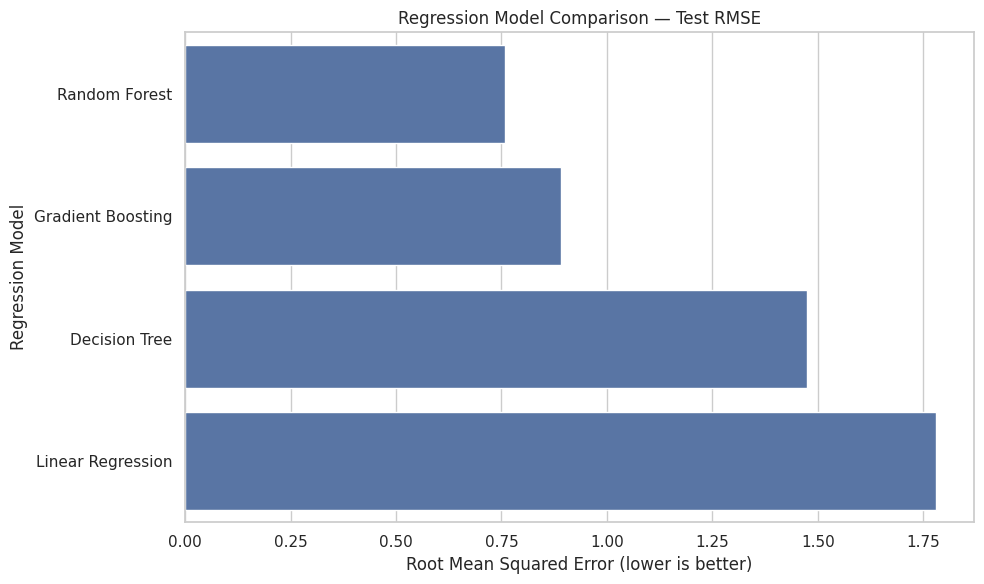

In [19]:
# Visualize the model comparison
figure_dir = Path("eda_figures")
figure_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Test_RMSE",
    y="Model"
)

plt.title("Regression Model Comparison — Test RMSE")
plt.xlabel("Root Mean Squared Error (lower is better)")
plt.ylabel("Regression Model")
plt.tight_layout()

plt.savefig(
    figure_dir / "07_model_comparison_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

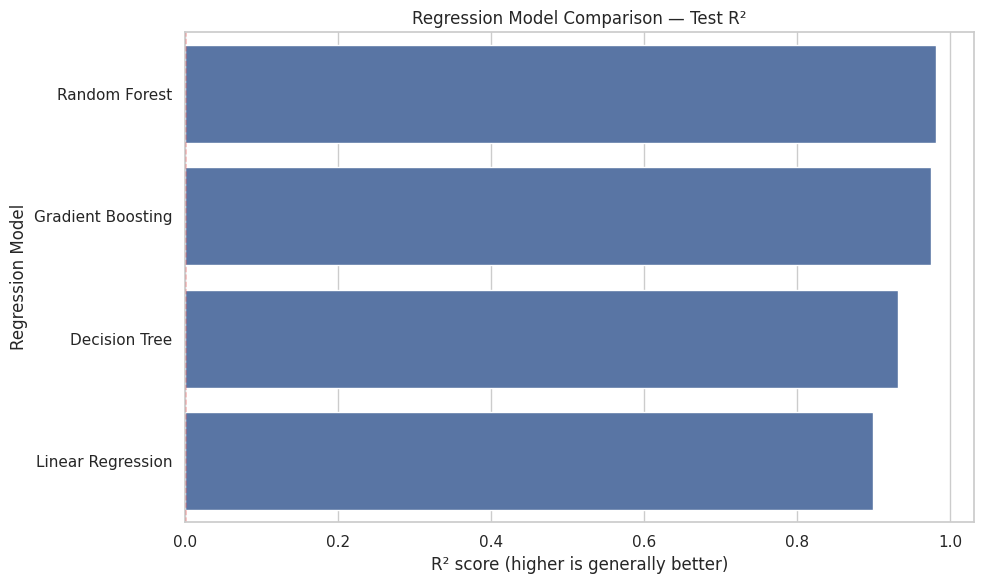

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Test_R2",
    y="Model"
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    linewidth=1
)

plt.title("Regression Model Comparison — Test R²")
plt.xlabel("R² score (higher is generally better)")
plt.ylabel("Regression Model")
plt.tight_layout()

plt.savefig(
    figure_dir / "08_model_comparison_r2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

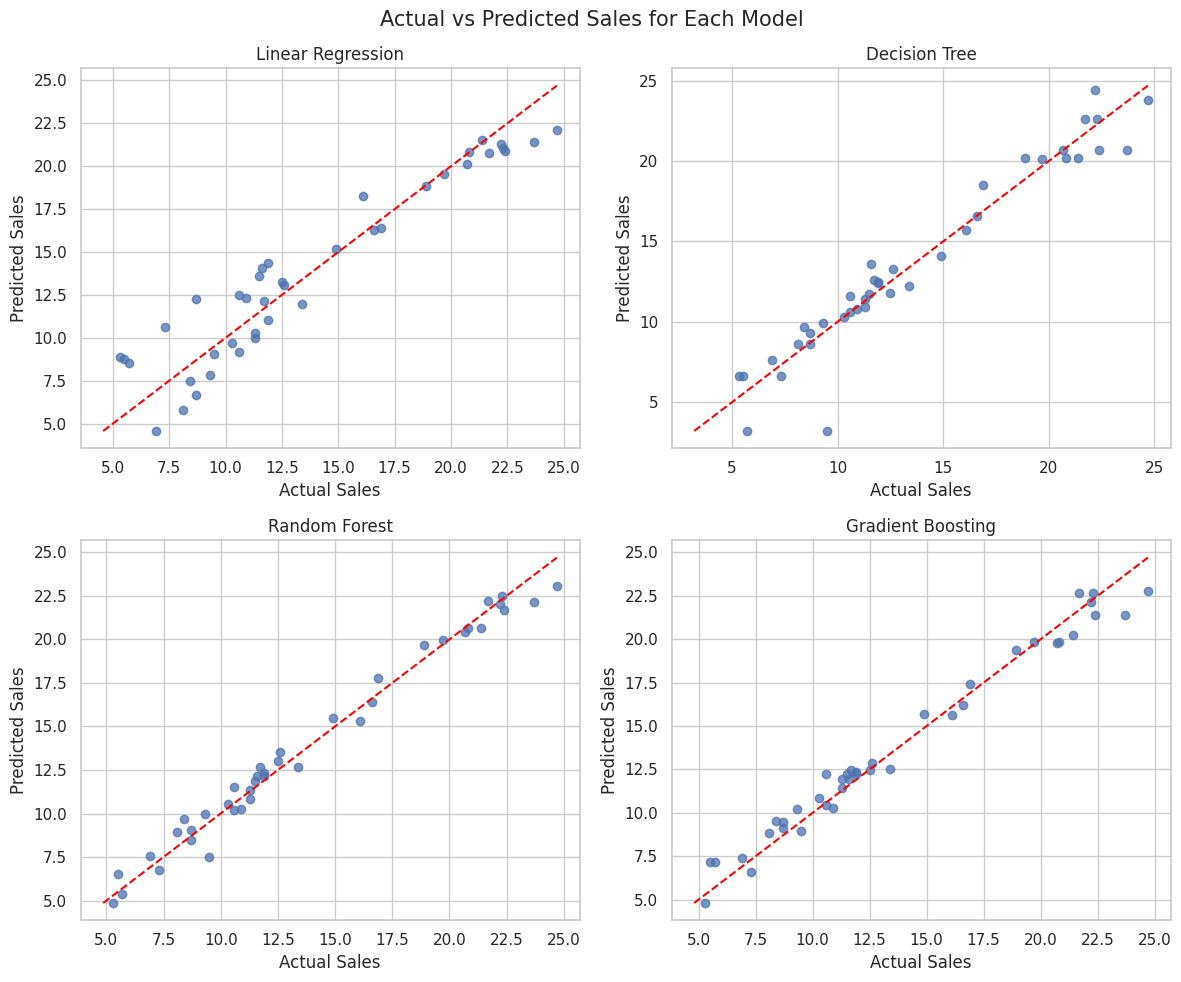

In [21]:
# Compare actual sales with predicted sales
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, predictions.items()):

    ax.scatter(
        y_test,
        y_pred,
        alpha=0.75
    )

    # Reference line: perfect predictions
    lower = min(y_test.min(), np.min(y_pred))
    upper = max(y_test.max(), np.max(y_pred))

    ax.plot(
        [lower, upper],
        [lower, upper],
        linestyle="--",
        color="red"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual Sales")
    ax.set_ylabel("Predicted Sales")

plt.suptitle(
    "Actual vs Predicted Sales for Each Model",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    figure_dir / "09_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Leading model by test RMSE: Random Forest
MAE:  0.6287
RMSE: 0.7572
R²:   0.9818


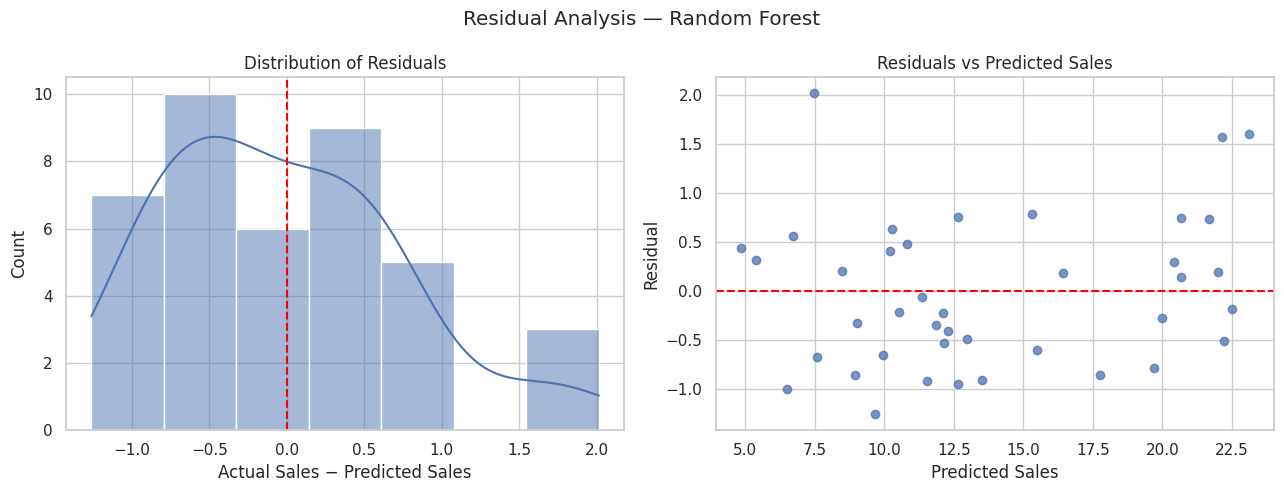

In [22]:
# Analyze the residuals of the leading model
best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]
best_predictions = predictions[best_model_name]

residuals = np.asarray(y_test) - best_predictions

print("Leading model by test RMSE:", best_model_name)
print(f"MAE:  {mean_absolute_error(y_test, best_predictions):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, best_predictions)):.4f}")
print(f"R²:   {r2_score(y_test, best_predictions):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Residual distribution
sns.histplot(
    residuals,
    kde=True,
    ax=axes[0]
)
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Distribution of Residuals")
axes[0].set_xlabel("Actual Sales − Predicted Sales")

# Residuals against predicted sales
axes[1].scatter(
    best_predictions,
    residuals,
    alpha=0.75
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals vs Predicted Sales")
axes[1].set_xlabel("Predicted Sales")
axes[1].set_ylabel("Residual")

plt.suptitle(f"Residual Analysis — {best_model_name}")
plt.tight_layout()

plt.savefig(
    figure_dir / "10_best_model_residuals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
# Validate the models using cross-validation
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    # Convert negative RMSE scores into positive values
    rmse_scores = -scores

    cv_results.append({
        "Model": name,
        "CV_RMSE_Mean": rmse_scores.mean(),
        "CV_RMSE_Std": rmse_scores.std()
    })

cv_results_df = pd.DataFrame(cv_results).sort_values(
    by="CV_RMSE_Mean"
).reset_index(drop=True)

display(cv_results_df.round(4))

cv_results_df.to_csv(
    "sales_cross_validation_results.csv",
    index=False
)

,Model,CV_RMSE_Mean,CV_RMSE_Std
0,Random Forest,0.8932,0.2000
1,Gradient Boosting,1.0317,0.2527
2,Decision Tree,1.4859,0.2441
3,Linear Regression,1.6758,0.2660


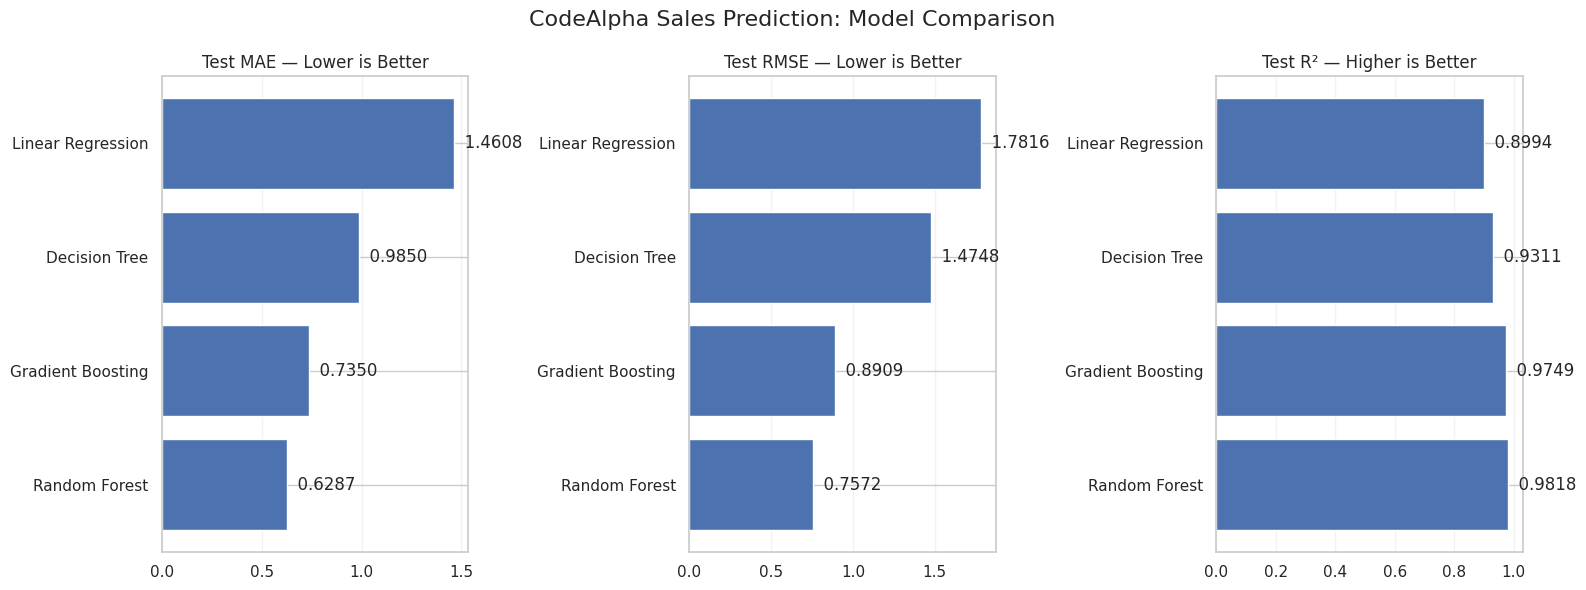

In [24]:

results_df = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Gradient Boosting",
        "Decision Tree",
        "Linear Regression"
    ],
    "Test_MAE": [0.6287, 0.7350, 0.9850, 1.4608],
    "Test_RMSE": [0.7572, 0.8909, 1.4748, 1.7816],
    "Test_R2": [0.9818, 0.9749, 0.9311, 0.8994]
})

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

metrics = [
    ("Test_MAE", "Test MAE — Lower is Better"),
    ("Test_RMSE", "Test RMSE — Lower is Better"),
    ("Test_R2", "Test R² — Higher is Better")
]

for ax, (metric, title) in zip(axes, metrics):
    data = results_df.sort_values(
        metric,
        ascending=(metric != "Test_R2")
    )

    bars = ax.barh(data["Model"], data[metric])
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.25)
    ax.set_axisbelow(True)

    for bar, value in zip(bars, data[metric]):
        ax.text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f"  {value:.4f}",
            va="center"
        )

fig.suptitle(
    "CodeAlpha Sales Prediction: Model Comparison",
    fontsize=16
)
fig.tight_layout()

# Save as scalable vector graphics
fig.savefig(
    "sales_model_comparison.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

**Feature Importance and Advertising Impact Analysis**

In [25]:
# Recreate the best model using the same training data
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully.")
print("Features:", X_train.columns.tolist())

Random Forest trained successfully.
Features: ['TV', 'Radio', 'Newspaper']


In [26]:
# Analyze Random Forest feature importance
# Extract built-in feature importance
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

importance_df.to_csv(
    "random_forest_feature_importance.csv",
    index=False
)

,Feature,Importance
0,TV,0.6247
1,Radio,0.3621
2,Newspaper,0.0132


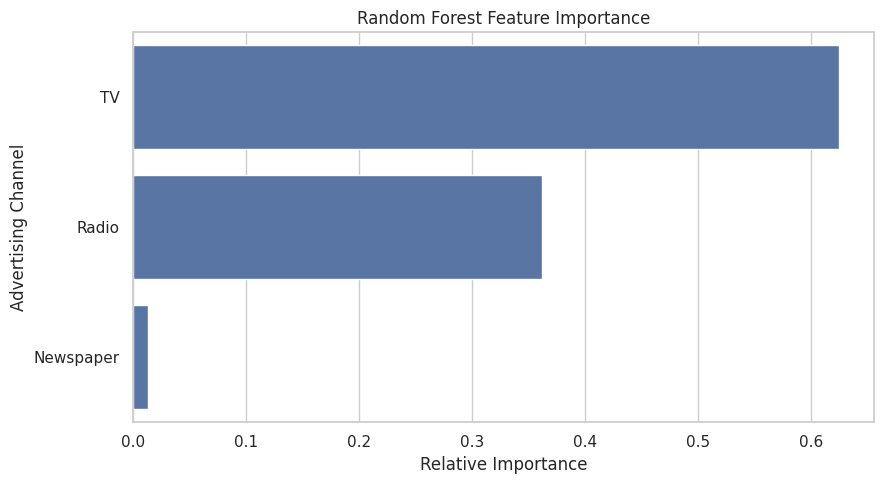

In [27]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Relative Importance")
plt.ylabel("Advertising Channel")
plt.tight_layout()

plt.savefig(
    figure_dir / "11_random_forest_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
# Validate importance with permutation importance
perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="neg_root_mean_squared_error",
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std
})

permutation_df = permutation_df.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

display(permutation_df.round(4))

permutation_df.to_csv(
    "permutation_feature_importance.csv",
    index=False
)

,Feature,Importance_Mean,Importance_Std
0,TV,5.8816,0.6067
1,Radio,3.4327,0.3467
2,Newspaper,-0.0004,0.0427


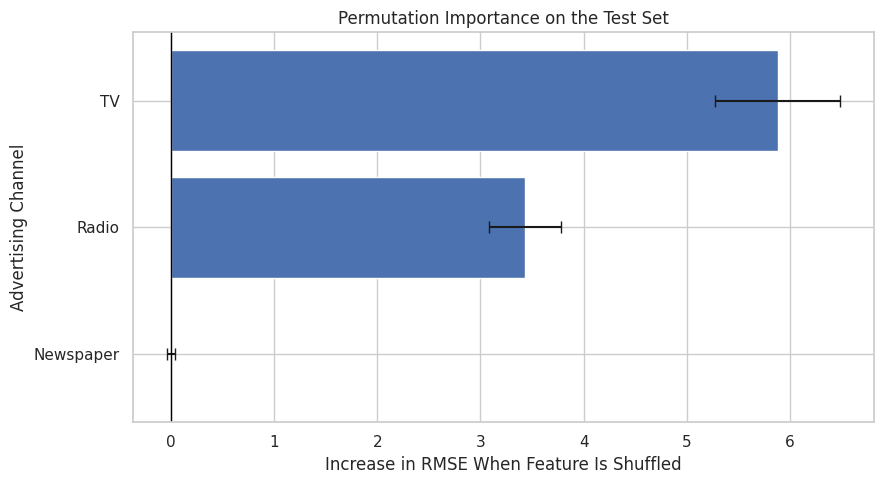

In [29]:
plt.figure(figsize=(9, 5))

plot_df = permutation_df.sort_values("Importance_Mean")

plt.barh(
    plot_df["Feature"],
    plot_df["Importance_Mean"],
    xerr=plot_df["Importance_Std"],
    capsize=4
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Permutation Importance on the Test Set")
plt.xlabel("Increase in RMSE When Feature Is Shuffled")
plt.ylabel("Advertising Channel")
plt.tight_layout()

plt.savefig(
    figure_dir / "12_permutation_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
# Examine linear regression coefficients
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

coefficients_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": linear_model.coef_
})

coefficients_df = pd.concat([
    coefficients_df,
    pd.DataFrame({
        "Feature": ["Intercept"],
        "Coefficient": [linear_model.intercept_]
    })
], ignore_index=True)

display(coefficients_df.round(4))

coefficients_df.to_csv(
    "linear_regression_coefficients.csv",
    index=False
)

,Feature,Coefficient
0,TV,0.0447
1,Radio,0.1892
2,Newspaper,0.0028
3,Intercept,2.9791


In [31]:
# Simulate advertising-spend changes
# Representative baseline based on the observed dataset
baseline = X.median().to_frame().T

scenarios = []

# Baseline prediction
baseline_prediction = rf_model.predict(baseline)[0]

scenarios.append({
    "Scenario": "Baseline",
    "TV": baseline.iloc[0]["TV"],
    "Radio": baseline.iloc[0]["Radio"],
    "Newspaper": baseline.iloc[0]["Newspaper"],
    "Predicted_Sales": baseline_prediction,
    "Change_vs_Baseline": 0.0
})

# Increase each channel individually by 10%
for feature in X.columns:
    scenario = baseline.copy()
    scenario[feature] = scenario[feature] * 1.10

    predicted_sales = rf_model.predict(scenario)[0]

    scenarios.append({
        "Scenario": f"{feature} +10%",
        "TV": scenario.iloc[0]["TV"],
        "Radio": scenario.iloc[0]["Radio"],
        "Newspaper": scenario.iloc[0]["Newspaper"],
        "Predicted_Sales": predicted_sales,
        "Change_vs_Baseline": predicted_sales - baseline_prediction
    })

scenario_df = pd.DataFrame(scenarios)

display(scenario_df.round(4))

scenario_df.to_csv(
    "advertising_impact_scenarios.csv",
    index=False
)

,Scenario,TV,Radio,Newspaper,Predicted_Sales,Change_vs_Baseline
0,Baseline,149.750,22.90,25.750,14.9855,0.0000
1,TV +10%,164.725,22.90,25.750,15.2960,0.3105
2,Radio +10%,149.750,25.19,25.750,15.1960,0.2105
3,Newspaper +10%,149.750,22.90,28.325,14.9850,-0.0005


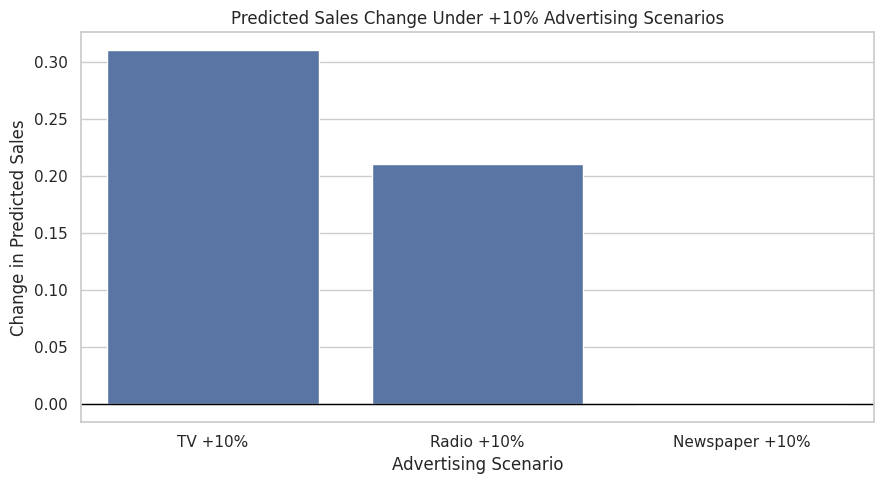

In [32]:
impact_df = scenario_df[
    scenario_df["Scenario"] != "Baseline"
].copy()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=impact_df,
    x="Scenario",
    y="Change_vs_Baseline"
)

plt.axhline(0, color="black", linewidth=1)
plt.title("Predicted Sales Change Under +10% Advertising Scenarios")
plt.xlabel("Advertising Scenario")
plt.ylabel("Change in Predicted Sales")
plt.tight_layout()

plt.savefig(
    figure_dir / "13_advertising_impact_scenarios.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

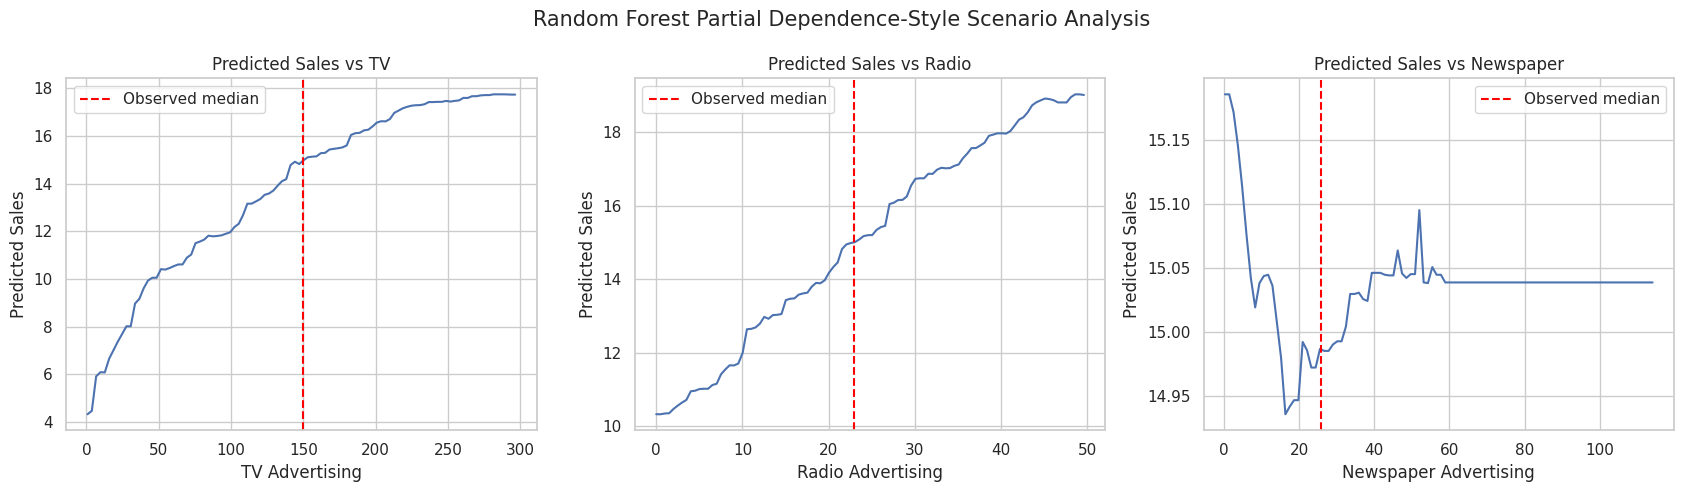

In [33]:
# Compare the model's predictions across a range of spending
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, feature in zip(axes, X.columns):
    feature_values = np.linspace(
        X[feature].min(),
        X[feature].max(),
        100
    )

    grid = pd.DataFrame(
        np.repeat(baseline.values, len(feature_values), axis=0),
        columns=baseline.columns
    )

    grid[feature] = feature_values
    predicted_sales = rf_model.predict(grid)

    ax.plot(feature_values, predicted_sales)
    ax.axvline(
        X[feature].median(),
        linestyle="--",
        color="red",
        label="Observed median"
    )

    ax.set_title(f"Predicted Sales vs {feature}")
    ax.set_xlabel(f"{feature} Advertising")
    ax.set_ylabel("Predicted Sales")
    ax.legend()

plt.suptitle(
    "Random Forest Partial Dependence-Style Scenario Analysis",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    figure_dir / "14_advertising_response_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
# Save a compact analysis summary
summary_path = Path("step6_analysis_summary.txt")

with open(summary_path, "w", encoding="utf-8") as file:
    file.write("CODEALPHA TASK 4: SALES PREDICTION\n")
    file.write("STEP 6: FEATURE IMPORTANCE AND ADVERTISING IMPACT\n\n")

    file.write("Random Forest feature importance:\n")
    file.write(importance_df.to_string(index=False))
    file.write("\n\nPermutation importance:\n")
    file.write(permutation_df.to_string(index=False))
    file.write("\n\nLinear regression coefficients:\n")
    file.write(coefficients_df.to_string(index=False))
    file.write("\n\nAdvertising scenarios:\n")
    file.write(scenario_df.to_string(index=False))

print(f"Step 6 summary saved to: {summary_path.resolve()}")

Step 6 summary saved to: /content/step6_analysis_summary.txt


**Hyperparameter Tuning and Final Model Selection**

In [35]:
# Tune Random Forest
# Define the Random Forest search space
rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_grid = GridSearchCV(
    estimator=RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ),
    param_grid=rf_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)

print(f"\nBest CV RMSE: {-rf_grid.best_score_:.4f}")

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Random Forest parameters:
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Best CV RMSE: 0.8852


In [36]:
# Tune Gradient Boosting
gb_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [1, 2, 3],
    "min_samples_leaf": [2, 4]
}

gb_grid = GridSearchCV(
    estimator=GradientBoostingRegressor(
        random_state=42
    ),
    param_grid=gb_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

gb_grid.fit(X_train, y_train)

print("Best Gradient Boosting parameters:")
print(gb_grid.best_params_)

print(f"\nBest CV RMSE: {-gb_grid.best_score_:.4f}")

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Gradient Boosting parameters:
{'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 200}

Best CV RMSE: 0.8511


In [37]:
# Compare tuned and baseline models
# Baseline models from previous Step
baseline_models = {
    "Random Forest (Baseline)": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting (Baseline)": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

# Tuned models selected by GridSearchCV
comparison_models = {
    **baseline_models,
    "Random Forest (Tuned)": rf_grid.best_estimator_,
    "Gradient Boosting (Tuned)": gb_grid.best_estimator_
}

comparison_rows = []

for name, model in comparison_models.items():

    # Baselines are fitted here; grid-search best estimators
    # are already fitted on X_train.
    if "Baseline" in name:
        model.fit(X_train, y_train)

    # Cross-validation on training data only
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    # Final evaluation on held-out test data
    test_pred = model.predict(X_test)

    comparison_rows.append({
        "Model": name,
        "CV_RMSE_Mean": -cv_scores.mean(),
        "CV_RMSE_Std": cv_scores.std(),
        "Test_MAE": mean_absolute_error(y_test, test_pred),
        "Test_RMSE": np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),
        "Test_R2": r2_score(y_test, test_pred)
    })

tuning_results = pd.DataFrame(comparison_rows)

tuning_results = tuning_results.sort_values(
    "CV_RMSE_Mean"
).reset_index(drop=True)

display(tuning_results.round(4))

tuning_results.to_csv(
    "sales_hyperparameter_tuning_results.csv",
    index=False
)

,Model,CV_RMSE_Mean,CV_RMSE_Std,Test_MAE,Test_RMSE,Test_R2
0,Gradient Boosting (Tuned),0.8511,0.1818,0.6481,0.7935,0.9801
1,Random Forest (Tuned),0.8852,0.2020,0.6143,0.7648,0.9815
2,Random Forest (Baseline),0.8932,0.2000,0.6287,0.7572,0.9818
3,Gradient Boosting (Baseline),1.0317,0.2527,0.7350,0.8909,0.9749


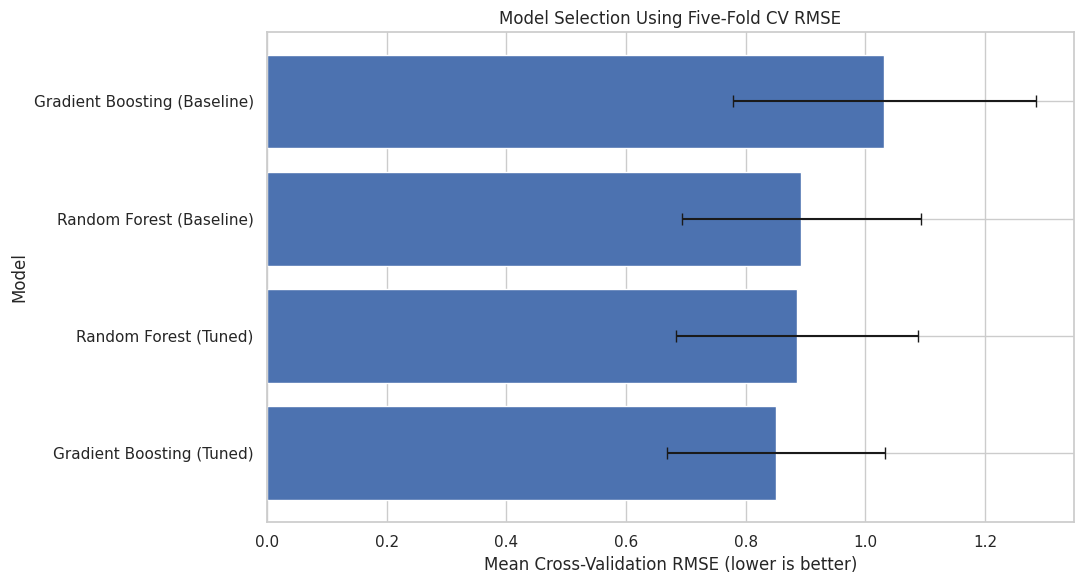

In [40]:
# Visualize cross-validation performance
plot_df = tuning_results.sort_values(
    "CV_RMSE_Mean",
    ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    plot_df["Model"],
    plot_df["CV_RMSE_Mean"],
    xerr=plot_df["CV_RMSE_Std"],
    capsize=4
)

plt.title("Model Selection Using Five-Fold CV RMSE")
plt.xlabel("Mean Cross-Validation RMSE (lower is better)")
plt.ylabel("Model")
plt.tight_layout()

plt.savefig(
    figure_dir / "15_hyperparameter_tuning_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
# Select the final model
best_model_name = tuning_results.loc[0, "Model"]
final_model = comparison_models[best_model_name]

# The selected model is already fitted, but refit explicitly
# on the complete training set for clarity.
final_model.fit(X_train, y_train)

final_predictions = final_model.predict(X_test)

final_mae = mean_absolute_error(
    y_test,
    final_predictions
)

final_rmse = np.sqrt(
    mean_squared_error(y_test, final_predictions)
)

final_r2 = r2_score(
    y_test,
    final_predictions
)

print("=" * 50)
print("FINAL SALES PREDICTION MODEL")
print("=" * 50)
print("Selected model:", best_model_name)
print(f"Test MAE:  {final_mae:.4f}")
print(f"Test RMSE: {final_rmse:.4f}")
print(f"Test R²:   {final_r2:.4f}")

FINAL SALES PREDICTION MODEL
Selected model: Gradient Boosting (Tuned)
Test MAE:  0.6481
Test RMSE: 0.7935
Test R²:   0.9801


In [42]:
# Save the final model
import joblib

model_path = Path("sales_prediction_final_model.joblib")

joblib.dump(final_model, model_path)

print(f"Final model saved to: {model_path.resolve()}")

Final model saved to: /content/sales_prediction_final_model.joblib


In [43]:
import joblib

loaded_model = joblib.load(
    "sales_prediction_final_model.joblib"
)

print("Final model loaded successfully.")

Final model loaded successfully.


In [44]:
# Test the saved model with a new example
example_advertising = pd.DataFrame({
    "TV": [150.0],
    "Radio": [25.0],
    "Newspaper": [30.0]
})

predicted_sales = loaded_model.predict(
    example_advertising
)

print(
    f"Predicted sales: {predicted_sales[0]:.4f}"
)

Predicted sales: 14.5600


In [45]:
# Evaluate the final model
# Generate predictions on the held-out test set
y_pred = final_model.predict(X_test)

# Calculate evaluation metrics
mae = np.mean(np.abs(np.asarray(y_test) - y_pred))
rmse = np.sqrt(np.mean((np.asarray(y_test) - y_pred) ** 2))

# R²: proportion of test-set variation explained by the model
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)

# Actual and predicted values
actual = np.asarray(y_test).reshape(-1)
predicted = np.asarray(y_pred).reshape(-1)

print("=" * 60)
print("FINAL SALES PREDICTION MODEL EVALUATION")
print("=" * 60)
print(f"Selected model : {best_model_name}")
print(f"Test MAE       : {mae:.4f}")
print(f"Test RMSE      : {rmse:.4f}")
print(f"Test R²        : {r2:.4f}")
print(f"Test samples   : {len(actual)}")
print("=" * 60)

# Save metric summary
evaluation_summary = pd.DataFrame([{
    "Final_Model": best_model_name,
    "Test_MAE": mae,
    "Test_RMSE": rmse,
    "Test_R2": r2,
    "Test_Samples": len(actual)
}])

evaluation_summary.to_csv(
    "sales_final_evaluation_metrics.csv",
    index=False
)

# Save actual versus predicted values
prediction_results = pd.DataFrame({
    "Actual_Sales": actual,
    "Predicted_Sales": predicted,
    "Residual": actual - predicted,
    "Absolute_Error": np.abs(actual - predicted)
})

prediction_results.to_csv(
    "sales_final_predictions.csv",
    index=False
)

print("\nSaved:")
print("- sales_final_evaluation_metrics.csv")
print("- sales_final_predictions.csv")


FINAL SALES PREDICTION MODEL EVALUATION
Selected model : Gradient Boosting (Tuned)
Test MAE       : 0.6481
Test RMSE      : 0.7935
Test R²        : 0.9801
Test samples   : 40

Saved:
- sales_final_evaluation_metrics.csv
- sales_final_predictions.csv


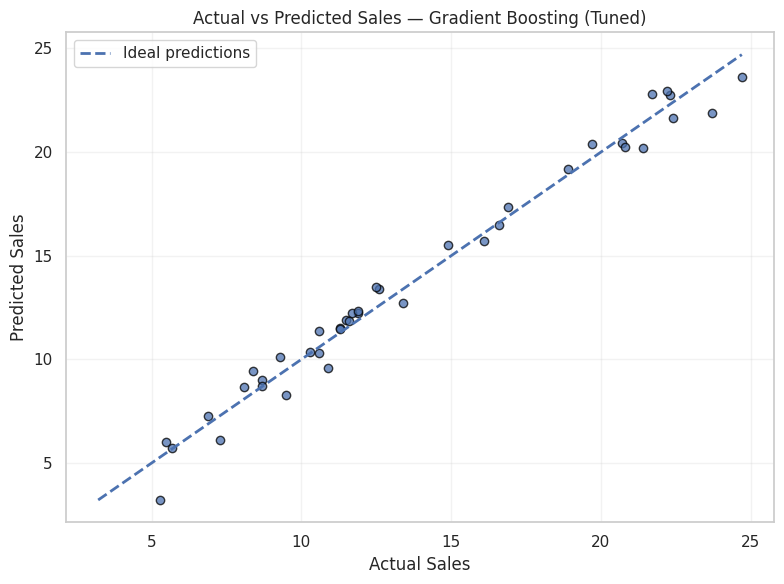

In [46]:
# Visualize actual vs. predicted sales

# Figure 16: Actual vs Predicted Sales
fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(actual, predicted, alpha=0.75, edgecolors="black")

# Ideal prediction line
lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())
ax.plot(
    [lower, upper], [lower, upper],
    linestyle="--", linewidth=2,
    label="Ideal predictions"
)

ax.set_xlabel("Actual Sales")
ax.set_ylabel("Predicted Sales")
ax.set_title(f"Actual vs Predicted Sales — {best_model_name}")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    figure_dir / "16_actual_vs_predicted_sales.png",
    dpi=300, bbox_inches="tight"
)
plt.savefig(
    figure_dir / "16_actual_vs_predicted_sales.svg",
    bbox_inches="tight"
)
plt.show()


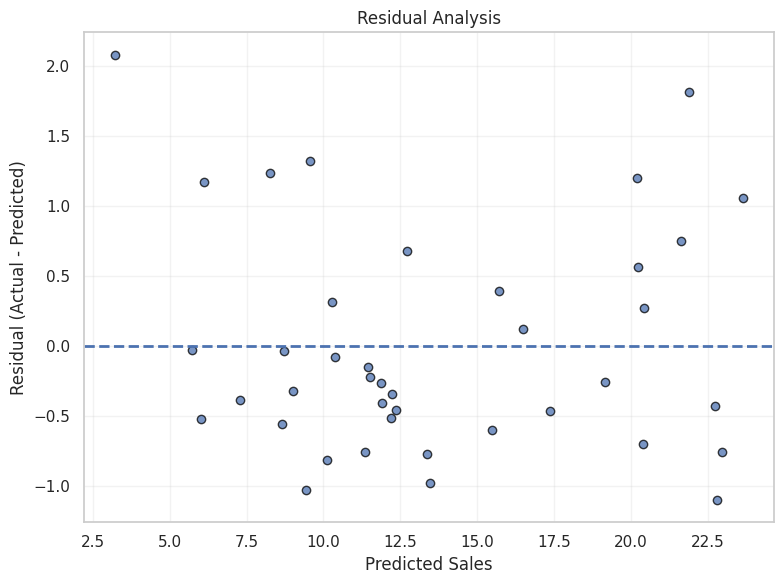

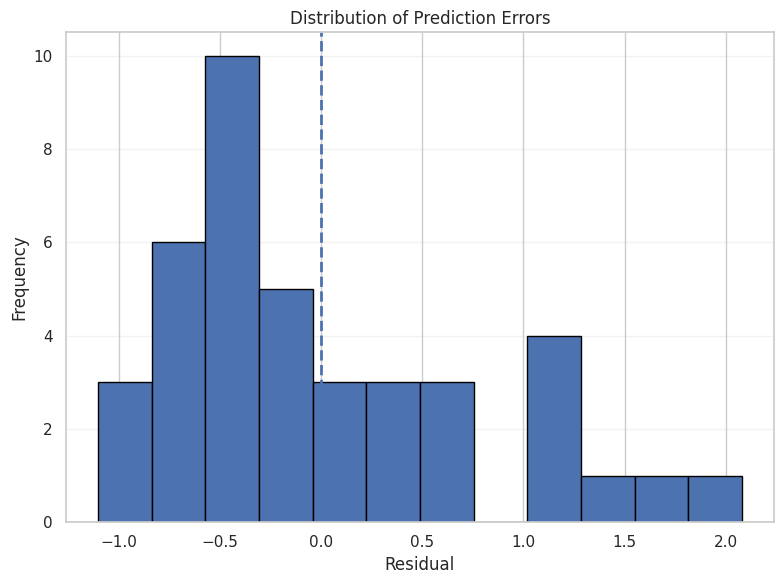

Residual mean: -0.0004
Residual standard deviation: 0.7935
Maximum absolute error: 2.0797
Figures saved in: /content/eda_figures


In [47]:
# Analyze prediction errors (residuals)

# Figure 17: Residuals vs Predicted Sales
residuals = actual - predicted

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(predicted, residuals, alpha=0.75, edgecolors="black")
ax.axhline(y=0, linestyle="--", linewidth=2)

ax.set_xlabel("Predicted Sales")
ax.set_ylabel("Residual (Actual - Predicted)")
ax.set_title("Residual Analysis")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    figure_dir / "17_residual_analysis.png",
    dpi=300, bbox_inches="tight"
)
plt.savefig(
    figure_dir / "17_residual_analysis.svg",
    bbox_inches="tight"
)
plt.show()

# Figure 18: Distribution of residuals
fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(residuals, bins=12, edgecolor="black")

ax.axvline(x=0, linestyle="--", linewidth=2)
ax.set_xlabel("Residual")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Prediction Errors")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    figure_dir / "18_residual_distribution.png",
    dpi=300, bbox_inches="tight"
)
plt.savefig(
    figure_dir / "18_residual_distribution.svg",
    bbox_inches="tight"
)
plt.show()

print("Residual mean:", round(residuals.mean(), 4))
print("Residual standard deviation:", round(residuals.std(), 4))
print("Maximum absolute error:", round(np.abs(residuals).max(), 4))
print("Figures saved in:", figure_dir.resolve())


In [48]:
# Compare against a simple baseline
# Simple benchmark
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

# Compare baseline with final model
comparison = pd.DataFrame([
    {
        "Model": "Mean Baseline",
        "MAE": mean_absolute_error(y_test, baseline_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, baseline_pred)),
        "R2": r2_score(y_test, baseline_pred)
    },
    {
        "Model": best_model_name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    }
])

comparison.to_csv("sales_final_vs_baseline.csv", index=False)

print(comparison.round(4).to_string(index=False))


                    Model    MAE   RMSE      R2
            Mean Baseline 4.9625 5.6315 -0.0048
Gradient Boosting (Tuned) 0.6481 0.7935  0.9801


In [49]:
# Generate report-ready conclusions
report_text = f"""
SALES PREDICTION USING MACHINE LEARNING
FINAL EVALUATION AND CONCLUSIONS
=================================

Selected model: {best_model_name}

Dataset and methodology
-----------------------
The analysis used TV, Radio, and Newspaper advertising expenditure
to predict Sales. The dataset was cleaned and explored before model
training. Model selection was informed by cross-validation, and final
performance was evaluated on the held-out test set.

Final test-set performance
--------------------------
Mean Absolute Error (MAE): {mae:.4f}
Root Mean Squared Error (RMSE): {rmse:.4f}
Coefficient of Determination (R²): {r2:.4f}
Number of test observations: {len(actual)}

Interpretation
--------------
MAE represents the average absolute prediction error in the units
of the Sales target. RMSE gives greater weight to large errors.
R² measures how much of the variation in the test-set Sales values
is explained by the model relative to predicting the test-set mean.

Limitations
-----------
The dataset is observational and contains advertising expenditures
and sales, but no randomized experiment. Relationships and feature
importance do not establish causal effects or prove advertising ROI.
The dataset does not contain a date column, so it cannot directly
support time-series forecasting or seasonal analysis.

The dataset is small, and test performance may vary with different
data splits. Cross-validation results and business validation should
also be considered before deployment.

Recommendations
---------------
Use the model as a decision-support tool for estimating sales under
advertising-spend scenarios, not as a guarantee of future sales.
Validate predictions on new data, monitor prediction errors, and
consider additional variables such as pricing, promotions, market
conditions, and time when available.

All reported metrics describe this dataset and evaluation setup;
they should not be assumed to generalize to every market or campaign.
"""

Path("sales_final_report_conclusions.txt").write_text(
    report_text.strip() + "\n",
    encoding="utf-8"
)

print(report_text)
print("\nSaved: sales_final_report_conclusions.txt")



SALES PREDICTION USING MACHINE LEARNING
FINAL EVALUATION AND CONCLUSIONS

Selected model: Gradient Boosting (Tuned)

Dataset and methodology
-----------------------
The analysis used TV, Radio, and Newspaper advertising expenditure
to predict Sales. The dataset was cleaned and explored before model
training. Model selection was informed by cross-validation, and final
performance was evaluated on the held-out test set.

Final test-set performance
--------------------------
Mean Absolute Error (MAE): 0.6481
Root Mean Squared Error (RMSE): 0.7935
Coefficient of Determination (R²): 0.9801
Number of test observations: 40

Interpretation
--------------
MAE represents the average absolute prediction error in the units
of the Sales target. RMSE gives greater weight to large errors.
R² measures how much of the variation in the test-set Sales values
is explained by the model relative to predicting the test-set mean.

Limitations
-----------
The dataset is observational and contains advertising 